# What has been the fate of 2020 young/old boreal forests over 5 years

+ bring AGBD trends and the kendall's tau analysis together with C accumulation to estimate the fate of C accumuation trajectories in the early 2020s
+ this is interesting b/c it gets at what impact fires are having on forests that otherwise might be accumulating C at fast rates.
+ it explains a result of the intensification of the fire cycle.

#### Literature
```bash
Yang, H., Ciais, P., Frappart, F. et al. Global increase in biomass carbon stock dominated by growth of northern young forests over past decade. Nat. Geosci. 16, 886–892 (2023). https://doi.org/10.1038/s41561-023-01274-4

Pulliainen et al 2024. Increase in gross primary production of boreal forests balanced out by increase in ecosystem respiration  https://doi.org/10.1016/j.rse.2024.114376

Burrell, Arden L., Sol Cooperdock, Stefano Potter, Logan T. Berner, Robert Hember, Matthew J. Macander, Xanthe J. Walker, et al. 2024. “ The Predictability of Near-Term Forest Biomass Change in Boreal North America.” Ecosphere 15(1): e4737. https://doi.org/10.1002/ecs2.4737

Chen, H.Y.H., Luo, Y., Reich, P.B., Searle, E.B. and Biswas, S.R. (2016), Climate change-associated trends in net biomass change are age dependent in western boreal forests of Canada. Ecol Lett, 19: 1150-1158. https://doi.org/10.1111/ele.12653  

Schepaschenko, D., Moltchanova, E., Fedorov, S. et al. Russian forest sequesters substantially more carbon than previously reported. Sci Rep 11, 12825 (2021). https://doi.org/10.1038/s41598-021-92152-9  

Wu & Hisano 2024. Spatial variation in boreal forest responses to global environmental change in western Canada. https://doi.org/10.1016/j.agrformet.2024.110140  

Europe 2019 drought: https://doi.org/10.5194/nhess-22-2201-2022
```

#  Results from zonal stats  (just ~1000 landscapes in this test)
`code/icesat2_boreal/notebooks/zonal_stats_hybas.ipynb`

In [1]:
#library(ggalluvial) # for sankey diagram

In [2]:
library(ggplot2)
library(dplyr)
library(tidyr)
library(RColorBrewer)
library(scales)
library(patchwork)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [3]:
library(viridis)
#library(mapproj)

Loading required package: viridisLite


Attaching package: ‘viridis’


The following object is masked from ‘package:scales’:

    viridis_pal




In [22]:
library(fs)
library(sf)

In [5]:
# Use the colors from your Python cmap - ordered by Kendall class sequence
trend_colors <- c(
  "strong_increase" = "#0000CC",    # Classes 1,2 - dark blue (first in Kendall order)
  "moderate_increase" = "#8080FF",  # Classes 3,4 - light blue 
  "stable" = "#CCCCCC",             # Classes 5,6 - gray
  "moderate_decline" = "#FF8080",   # Classes 7,8 - light red
  "strong_decline" = "#CC0000"      # Classes 9,10 - dark red (last in Kendall order)
)

# Define the desired order for age classes
age_class_order <- c("non-forest", "young", "maturing", "mature", "old-growth")

# Define the desired order for trend classes (following Kendall class order)
trend_class_order <- c("strong_increase", "moderate_increase", "stable", "moderate_decline", "strong_decline")

In [6]:
# Create labels for the legend (keeping the order)
trend_labels <- c(
  "strong_increase" = "Increase\n(strong)",
  "moderate_increase" = "Increase\n(moderate)", 
  "stable" = "Stable",
  "moderate_decline" = "Decline\n(moderate",
  "strong_decline" = "Decline\n(strong)"
)

age_labels <- c(
  "non-forest" = "Non-Forest",
  "young" = "Young Forest",
  "maturing" = "Maturing Forest", 
  "mature" = "Mature Forest",
  "old-growth" = "Old Growth Forest"
)

## Read in biomass change summary (done with `calculate_biomass_change.py` after `zonal_stats_landscapes.py`)

In [7]:
INDIR = '/projects/my-public-bucket/local_output/zonal_stats_landscapes/hybas_test_subset_02570'

### Mapping functions and vars

In [23]:
source('/projects/code/3dsi/boreal_map_functions.R') 

[1] "MAAP"
[1] "MAAP"


In [9]:
crs_canalb = "+proj=aea +lat_0=40 +lon_0=180 +lat_1=50 +lat_2=70 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs"
crs_albers = "+proj=aea +lat_1=50 +lat_2=70 +lat_0=40 +lon_0=180 +x_0=0 +y_0=0 +ellps=GRS80 +datum=NAD83 +units=m +no_defs"
crs_gcs = "+proj=longlat +ellps=WGS84 +datum=WGS84 +no_defs"

### This file has the tiles used for the 2020 map (boreal and >51.6) (DAAC)

In [10]:
boreal_tile_index_path = '/projects/my-public-bucket/databank/daac/boreal_tiles_v004_ORNLDAAC.gpkg'

In [11]:
boreal_tindex = st_read(boreal_tile_index_path) %>% sf::st_transform(4326)

Reading layer `boreal_tiles_v004_ORNLDAAC' from data source 
  `/projects/my-public-bucket/databank/daac/boreal_tiles_v004_ORNLDAAC.gpkg' 
  using driver `GPKG'
Simple feature collection with 3902 features and 1 field
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: 43.75195 xmax: 180 ymax: 78.53133
Geodetic CRS:  WGS 84


In [12]:
map_extent_boreal = raster::extent(-180,180,42.5,90)

### Maps of landscapes

In [13]:
data_polygon_biomass_change_simple = read.csv(paste0(INDIR, '/results_polygon_biomass_change_simplified_long_format.csv'))
data_polygon_biomass_change_simple = data_polygon_biomass_change_simple %>%
    filter(value_type == 'agb_2020_to_agb_2025') %>%
    rename(HYBAS_ID = polygon_id)

head(data_polygon_biomass_change_simple,3)

,HYBAS_ID,value_type,biomass_mean_pg,biomass_std_pg,change_percent,prob_increase
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,2080033570,agb_2020_to_agb_2025,7.062645e-05,4.857997e-07,6.893007,1
2,2080033580,agb_2020_to_agb_2025,2.486839e-04,5.910071e-07,20.366041,1
3,2080033610,agb_2020_to_agb_2025,7.214441e-05,5.288590e-07,6.284262,1


In [14]:
landscapes = st_read(paste0(INDIR, '/results.gpkg')) %>% 
    dplyr::select(HYBAS_ID) %>%
    left_join(data_polygon_biomass_change_simple,  by = c( "HYBAS_ID" ))

Reading layer `results' from data source 
  `/projects/my-public-bucket/local_output/zonal_stats_landscapes/hybas_test_subset_02570/results.gpkg' 
  using driver `GPKG'
Simple feature collection with 2570 features and 802 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -168.1339 ymin: 45.28796 xmax: 153.5629 ymax: 72.62083
Geodetic CRS:  WGS 84


In [15]:
dim(landscapes)

[1] 2570    7

In [16]:
wwf_circ_dis_fn

/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp

In [17]:
theme_plot_text = list(
            theme(
                legend.title=element_text(size=rel(1.2)), # 1.25
                legend.text=element_text(size=rel(1)), #0.75
                plot.caption = element_text(size = 7)
                )
            )

## Map landscape change (%) in aboveground C

In [26]:
library(sp) # needs to be loaded after sf and maybe some other packages so that DO_MAP_BOREAL_SP() works?

Regions defined for each Polygons


[1] "Using sf and coercing to Spatial object..."
Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


Regions defined for each Polygons
Regions defined for each Polygons
Regions defined for each Polygons


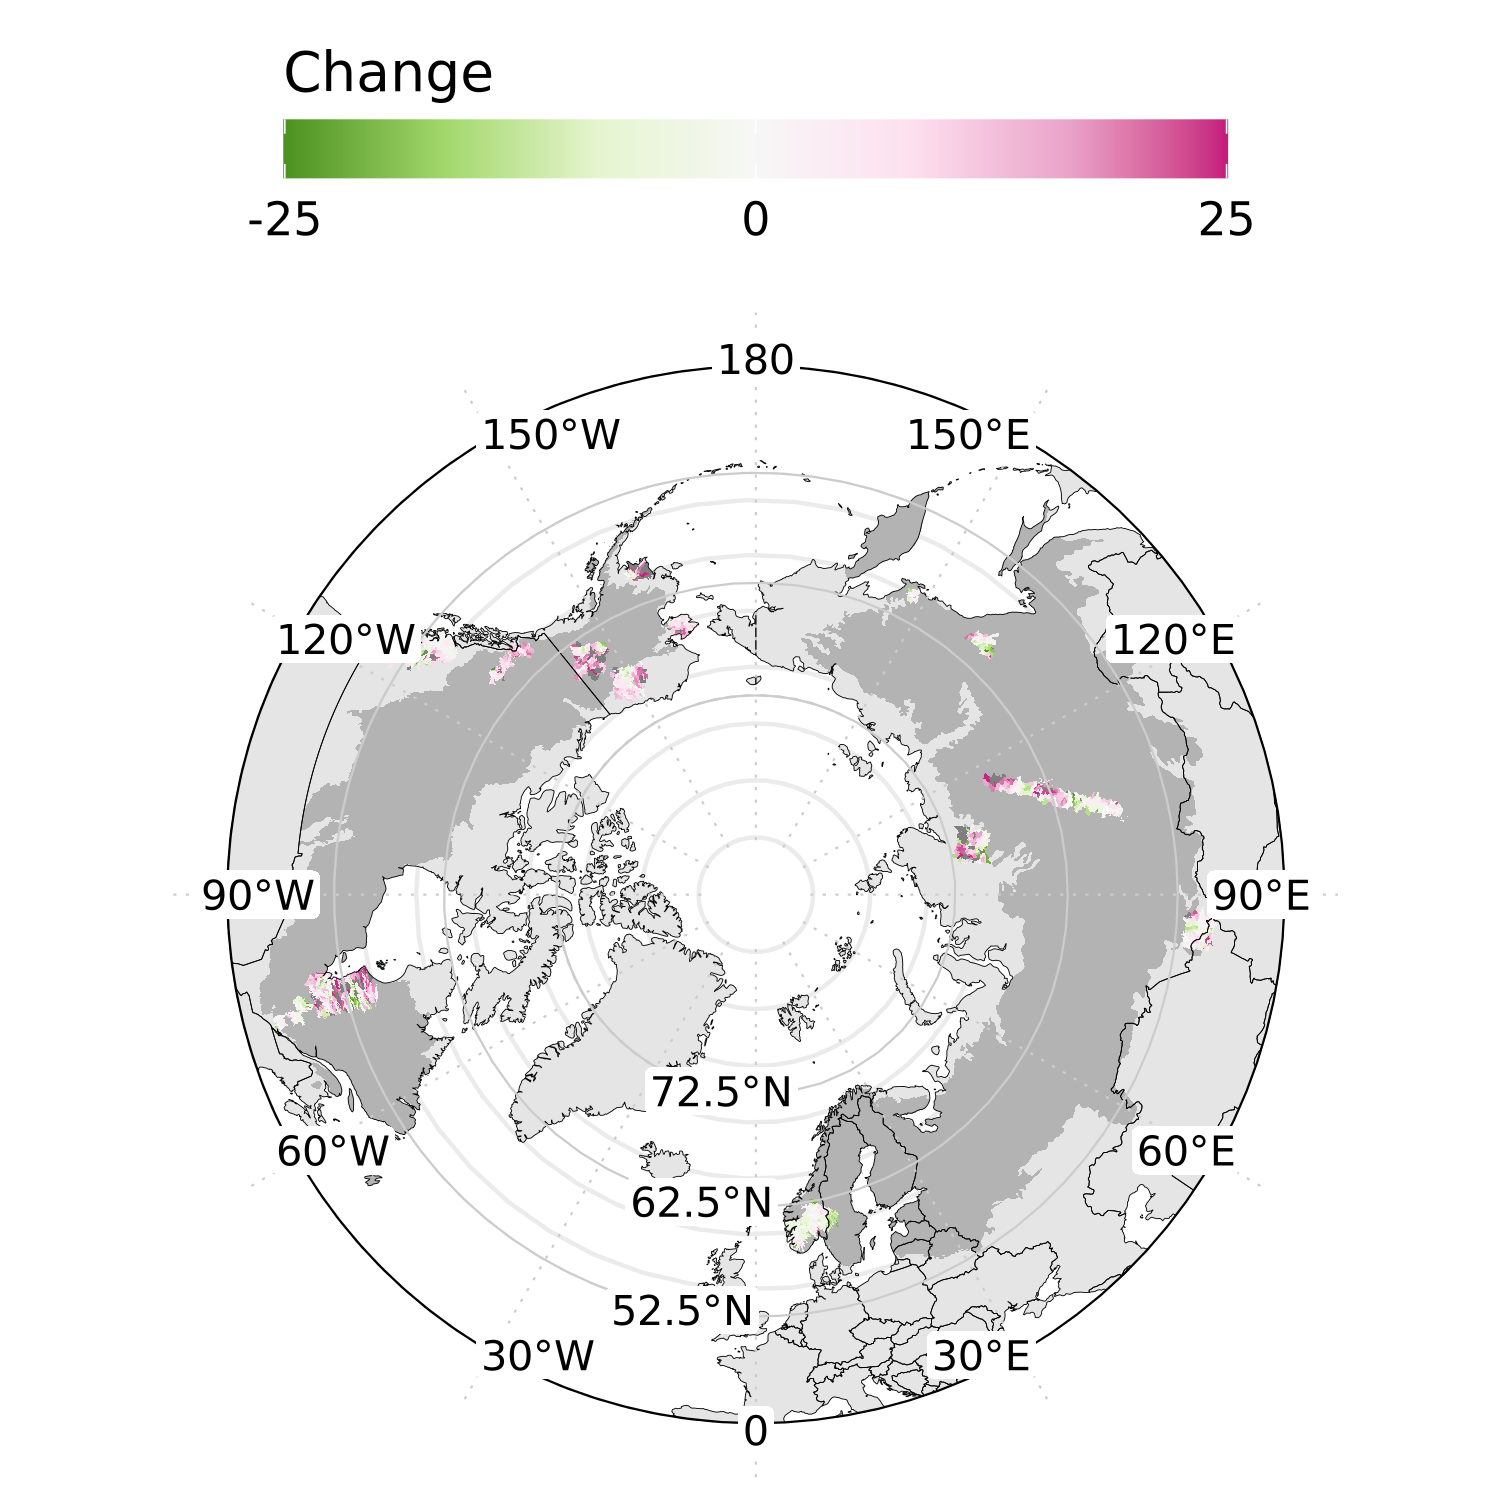

In [25]:
options(repr.plot.width = 5, repr.plot.height = 5, repr.plot.res = 300)

map_theme = list(
    theme(legend.text=element_text(size=rel(0.35))),
    guides(fill=guide_colourbar(title='Change', title.position = "top", label.position = "bottom"
                               , keywidth = unit(8, "cm"), keyheight = unit(.5, "cm")
                               )
           ),
    scale_fill_distiller(palette = 'PiYG' , direction=-1,
                       , breaks=c(-25,0,25)
                       , limits = c(-25,25),
                       #, labels=comma
                      #, trans='log'
                      )
    )

LAYER_LIST = list(geom_polygon(data = fortify_sf(landscapes) %>% drop_na(), aes(x = long, y = lat, group = group, fill=change_percent), size=0.1))

DO_MAP_BOREAL_SP(MAP_EXTENT = map_extent_boreal, BOREAL_SHP_FN = wwf_circ_dis_fn
                 , LAYER_LIST = LAYER_LIST
                ) + map_theme + theme_plot_text

## Get `boreal` landscapes and assign `ECO_NAME` and assign `boreal` and `not boreal`

In [27]:
library(lwgeom)  # For st_geod_area if needed

Linking to liblwgeom 3.0.0beta1 r16016, GEOS 3.12.1, PROJ 9.4.0


Attaching package: ‘lwgeom’


The following object is masked from ‘package:sf’:

    st_perimeter




In [55]:
# Function to calculate majority overlap
majority_area_join <- function(target_sf, overlay_sf, target_col, overlay_cols) {
  # Ensure both are valid geometries
  target_sf <- st_make_valid(target_sf)
  overlay_sf <- st_make_valid(overlay_sf)
  
  # Perform intersection
  intersections <- st_intersection(target_sf, overlay_sf)
  
  # Calculate areas of intersections
  intersections$area <- as.numeric(st_area(intersections))
  
  # Convert overlay_cols to character if it's a single string
  if(is.character(overlay_cols) && length(overlay_cols) == 1) {
    overlay_cols <- overlay_cols
  }
  
  # Create the selection vector - include target_col, overlay_cols, and area
  select_cols <- c(target_col, overlay_cols)
  
  # Group by target feature and find the overlay feature with maximum area
  majority_overlaps <- intersections %>%
    st_drop_geometry() %>%
    group_by(!!sym(target_col)) %>%
    slice_max(area, n = 1, with_ties = FALSE) %>%
    select(all_of(select_cols))
  
  # Join back to original target
  result <- target_sf %>%
    left_join(majority_overlaps, by = target_col)
  
  return(result)
}

In [29]:
wwf_circ_dis_fn

/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp

In [30]:
# Read in the spatial datasets
# Replace these paths with your actual file paths
wwf_ecoregions <- st_read('/projects/my-public-bucket/databank/wwf_terr_ecos.gpkg')
boreal_dissolved <- st_read(wwf_circ_dis_fn)

Reading layer `wwf_terr_ecos' from data source 
  `/projects/my-public-bucket/databank/wwf_terr_ecos.gpkg' using driver `GPKG'
Simple feature collection with 14458 features and 18 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -89.89197 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


In [75]:
# Ensure all datasets are in the same CRS (preferably projected for area calculations)
# Use a suitable projection for your study area, e.g., Albers Equal Area
target_crs <- st_crs("+proj=aea +lat_0=50 +lon_0=-154 +lat_1=55 +lat_2=65 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs")

landscapes <- st_transform(landscapes, target_crs)
wwf_ecoregions <- st_transform(wwf_ecoregions, target_crs)
boreal_dissolved <- st_transform(boreal_dissolved, target_crs)

# Add unique identifier to hydrobasins if it doesn't exist
if(!"HYBAS_ID" %in% names(landscapes)) {
  landscapes$HYBAS_ID <- 1:nrow(landscapes)
}

print("Performing ecoregion majority area join...")
# Join hydrobasins with ecoregions using majority area rule
landscapes_with_eco <- majority_area_join(
  target_sf = landscapes,
  overlay_sf = wwf_ecoregions,
  target_col = "HYBAS_ID",  # Adjust if your ID column has different name
  overlay_cols = c("ECO_NAME","BIOME")   # Adjust if your ecoregion name column has different name
)

print("Performing boreal boundary join...")
# Create a simple boreal indicator (TRUE/FALSE) based on overlap with boreal polygon
# For this, we'll use a different approach since it's just TRUE/FALSE

# Method 1: Majority area rule for boreal
boreal_dissolved$domain <- 'boreal'
boreal_dissolved$domain_id <- 1

landscapes_with_boreal <- majority_area_join(
  target_sf = landscapes_with_eco,
  overlay_sf = boreal_dissolved,
  target_col = "HYBAS_ID",
  overlay_cols = c("domain")
)

# Set NA values to FALSE (hydrobasins not overlapping with boreal)
landscapes_with_boreal$domain[is.na(landscapes_with_boreal$domain)] <- 'not boreal'

# Alternative: Create a lookup dataframe if you prefer
biome_lookup <- data.frame(
  BIOME = c(1:14, 98, 99),
  BIOME_NAME = c(
    "Tropical & Subtropical Moist Broadleaf Forests",
    "Tropical & Subtropical Dry Broadleaf Forests", 
    "Tropical & Subtropical Coniferous Forests",
    "Temperate Broadleaf & Mixed Forests",
    "Temperate Conifer Forests",
    "Boreal Forests/Taiga",
    "Tropical & Subtropical Grasslands, Savannas & Shrublands",
    "Temperate Grasslands, Savannas & Shrublands", 
    "Flooded Grasslands & Savannas",
    "Montane Grasslands & Shrublands",
    "Tundra",
    "Mediterranean Forests, Woodlands & Scrub",
    "Deserts & Xeric Shrublands",
    "Mangroves",
    "Lake",
    "Rock and Ice"
  )
)

# Clean up the final dataset
final_landscapes <- landscapes_with_boreal %>%
  select(-any_of(c("domain_id"))) %>%  # Remove temporary columns if they exist
  relocate(ECO_NAME, domain, .after = last_col())  %>% # Move new columns to end
    left_join(biome_lookup, by = "BIOME")

# Print summary
print(paste("Total landscapes:", nrow(final_landscapes)))
print(paste("landscapes with ecoregion data:", sum(!is.na(final_landscapes$ECO_NAME))))
print(paste("Boreal landscapes:", sum(final_landscapes$domain_id, na.rm = TRUE)))
print("Ecoregion summary:")
print(table(final_landscapes$ECO_NAME, useNA = "ifany"))
print("Boreal summary:")
print(table(final_landscapes$domain, useNA = "ifany"))

[1] "Performing ecoregion majority area join..."


Warning message:
“attribute variables are assumed to be spatially constant throughout all geometries”


[1] "Performing boreal boundary join..."


Warning message:
“attribute variables are assumed to be spatially constant throughout all geometries”


[1] "Total landscapes: 2570"
[1] "landscapes with ecoregion data: 2570"
[1] "Boreal landscapes: 0"
[1] "Ecoregion summary:"

                   Alaska-St. Elias Range tundra 
                                              13 
                  Altai alpine meadow and tundra 
                                              28 
          Altai montane forest and forest steppe 
                                              44 
                    Altai steppe and semi-desert 
                                              33 
                           Arctic coastal tundra 
                                               1 
                         Arctic foothills tundra 
                                              37 
                         Beringia lowland tundra 
                                              23 
                          Beringia upland tundra 
                                             110 
       British Columbia mainland coastal forests 
                         

In [76]:
head(final_landscapes)

,HYBAS_ID,value_type,biomass_mean_pg,biomass_std_pg,change_percent,prob_increase,BIOME,ECO_NAME,domain,BIOME_NAME,geom
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<GEOMETRY [m]>
1,3080710130,agb_2020_to_agb_2025,-2.060706e-05,4.736688e-07,-10.395356,0.0000000,10,Altai alpine meadow and tundra,not boreal,Montane Grasslands & Shrublands,"POLYGON ((-4778557 5906382,..."
2,3089000441,agb_2020_to_agb_2025,4.141712e-08,1.623962e-08,9.158081,0.9946196,13,Junggar Basin semi-desert,not boreal,Deserts & Xeric Shrublands,"POLYGON ((-4864443 6086196,..."
3,3080699781,agb_2020_to_agb_2025,2.123513e-06,4.866845e-08,25.379169,1.0000000,8,Altai steppe and semi-desert,not boreal,"Temperate Grasslands, Savannas & Shrublands","POLYGON ((-4727689 6081275,..."
4,3080696721,agb_2020_to_agb_2025,8.543215e-06,2.716886e-07,8.657270,1.0000000,8,Altai steppe and semi-desert,not boreal,"Temperate Grasslands, Savannas & Shrublands","POLYGON ((-4722785 6085356,..."
5,3080694851,agb_2020_to_agb_2025,3.547224e-05,4.736055e-07,11.270058,1.0000000,8,Altai steppe and semi-desert,not boreal,"Temperate Grasslands, Savannas & Shrublands",MULTIPOLYGON (((-4707857 60...
6,3080696722,agb_2020_to_agb_2025,9.870736e-06,2.314967e-07,7.424767,1.0000000,8,Altai steppe and semi-desert,not boreal,"Temperate Grasslands, Savannas & Shrublands","POLYGON ((-4699890 6086791,..."


In [77]:
data_polygon_biomass_change_long = read.csv(path(INDIR, '/results_polygon_biomass_change_long_format.csv')) %>%
                            mutate(age_class = factor(age_class, levels = age_class_order)) %>%
                            left_join(final_landscapes %>% select(HYBAS_ID,ECO_NAME,domain,BIOME_NAME) %>% as.data.frame(), by = c('polygon_id'='HYBAS_ID'))
head(data_polygon_biomass_change_long)

,polygon_id,age_class,trend_class,value_type,biomass_mean_pg,biomass_std_pg,change_percent,prob_increase,ECO_NAME,domain,BIOME_NAME,geom
,<dbl>,<fct>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<POLYGON [m]>
1,2080033570,non-forest,strong_decline,agb_2020,1.271412e-06,1.518581e-08,NA,NA,Scandinavian and Russian taiga,boreal,Boreal Forests/Taiga,"POLYGON ((2261500 7722004, ..."
2,2080033570,non-forest,strong_decline,agb_2025,8.097193e-07,1.257671e-08,NA,NA,Scandinavian and Russian taiga,boreal,Boreal Forests/Taiga,"POLYGON ((2261500 7722004, ..."
3,2080033570,non-forest,strong_decline,agb_2020_to_agb_2025,-4.616922e-07,2.007499e-08,-36.31336,0,Scandinavian and Russian taiga,boreal,Boreal Forests/Taiga,"POLYGON ((2261500 7722004, ..."
4,2080033570,non-forest,moderate_decline,agb_2020,0.000000e+00,0.000000e+00,NA,NA,Scandinavian and Russian taiga,boreal,Boreal Forests/Taiga,"POLYGON ((2261500 7722004, ..."
5,2080033570,non-forest,moderate_decline,agb_2025,0.000000e+00,0.000000e+00,NA,NA,Scandinavian and Russian taiga,boreal,Boreal Forests/Taiga,"POLYGON ((2261500 7722004, ..."
6,2080033570,non-forest,moderate_decline,agb_2020_to_agb_2025,0.000000e+00,0.000000e+00,NA,0,Scandinavian and Russian taiga,boreal,Boreal Forests/Taiga,"POLYGON ((2261500 7722004, ..."


In [64]:
dim(data_polygon_biomass_change_long)

[1] 192750     12

In [78]:
smry_age_trend_type = data_polygon_biomass_change_long %>%
    group_by(age_class, trend_class, value_type, BIOME_NAME) %>%
    summarise(
        n_landscapes = n(),
        biomass_mean_pg = sum(biomass_mean_pg, na.rm=TRUE),
        biomass_std_pg = sum(biomass_std_pg, na.rm=TRUE),
        change_percent = sum(change_percent, na.rm=TRUE), # wrong
        #prob_increase = prob_increase/n_landscapes,
        .groups = 'drop'
    ) %>%
    filter(change_percent != 0 ) %>% # this removes trend classes that dont exist (moderate decline)
    droplevels()

smry_trend_type = data_polygon_biomass_change_long %>%
    group_by(trend_class, value_type, BIOME_NAME) %>%
    summarise(
        n_landscapes = n()/length(levels(data_polygon_biomass_change_long$age_class)),
        biomass_mean_pg = sum(biomass_mean_pg, na.rm=TRUE),
        biomass_std_pg = sum(biomass_std_pg, na.rm=TRUE),
        change_percent = sum(change_percent, na.rm=TRUE), # wrong
        #prob_increase = sum(prob_increase)/n_landscapes,
        .groups = 'drop'
    ) %>% 
    filter(change_percent != 0 ) %>% # this removes trend classes that dont exist (moderate decline)
droplevels()


# REVERSE the order for the legend display
trend_class_order_reversed <- rev(trend_class_order)

bars_list = list(
      # Add bars
  geom_bar(stat = "identity", position = "dodge", width = 0.7),
  # Add 0 line
    geom_hline(aes(yintercept=0), linetype='dashed'),
  # Add error bars
  geom_errorbar(aes(ymin = ((biomass_mean_pg - biomass_std_pg)/2 )* 1e3, 
                    ymax = ((biomass_mean_pg + biomass_std_pg)/2 ) * 1e3),
                position = position_dodge(width = 0.7),
                width = 0.25,  # Width of error bar caps
                color = "black",
                size = 0.5),
  
  scale_fill_manual(values = trend_colors,
                    name = "Trend class ",
                    labels = trend_labels,
                    breaks = trend_class_order),
  
  scale_y_continuous(),
  
  labs(y = 'Change in\naboveground C [Tg]\n2020-2025' , x=NULL),
  
  theme_bw(),
  theme(
    plot.title = element_text(size = 14, face = "bold"),
    plot.subtitle = element_text(size = 12, color = "gray60"),
    axis.text = element_text(size = 10, angle = 90),
    axis.text.x = element_blank(),
    axis.title = element_text(size = 11, face = "bold"),
    legend.position = "right",
    legend.title.position = "top",
    legend.title = element_text(size = 12, face = "bold"),
    legend.text = element_text(size = 10)
  )
)

p_smry_trend = ggplot(
    smry_trend_type %>% 
       filter(value_type == 'agb_2020_to_agb_2025')
       , aes(x = factor(value_type), y = biomass_mean_pg/2 * 1e3, fill = trend_class)) +   # <---- NOTE: Dividing by 2 to take AGB to C
  
  bars_list +
  #annotate('text', hjust=-0.15, vjust=1.5, x=-Inf, y=Inf, label=paste0("n=",length(unique(data_polygon_biomass_change_long$polygon_id))," landscapes")) +
    geom_text(hjust=-0.15, vjust=1.5, x=-Inf, y=Inf, aes(label=paste0('n landscapes = ',n_landscapes) ), size=2) +
  facet_wrap(~BIOME_NAME, ncol=8)

p_smry_age_trend = ggplot(
    smry_age_trend_type %>% 
       filter(value_type == 'agb_2020_to_agb_2025')
       , aes(x = factor(value_type), y = biomass_mean_pg/2 * 1e3, fill = trend_class)) +   # <---- NOTE: Dividing by 2 to take AGB to C
  geom_text(hjust=-0.15, vjust=1.5, x=-Inf, y=Inf, aes(label=paste0('n landscapes = ',n_landscapes) ), size=2) +
  bars_list+
  facet_grid(BIOME_NAME~age_class,scales = 'free_x')

## Summary across landscapes - still need `boreal` and `non_boreal` - working in `landscape_boreal.ipynb

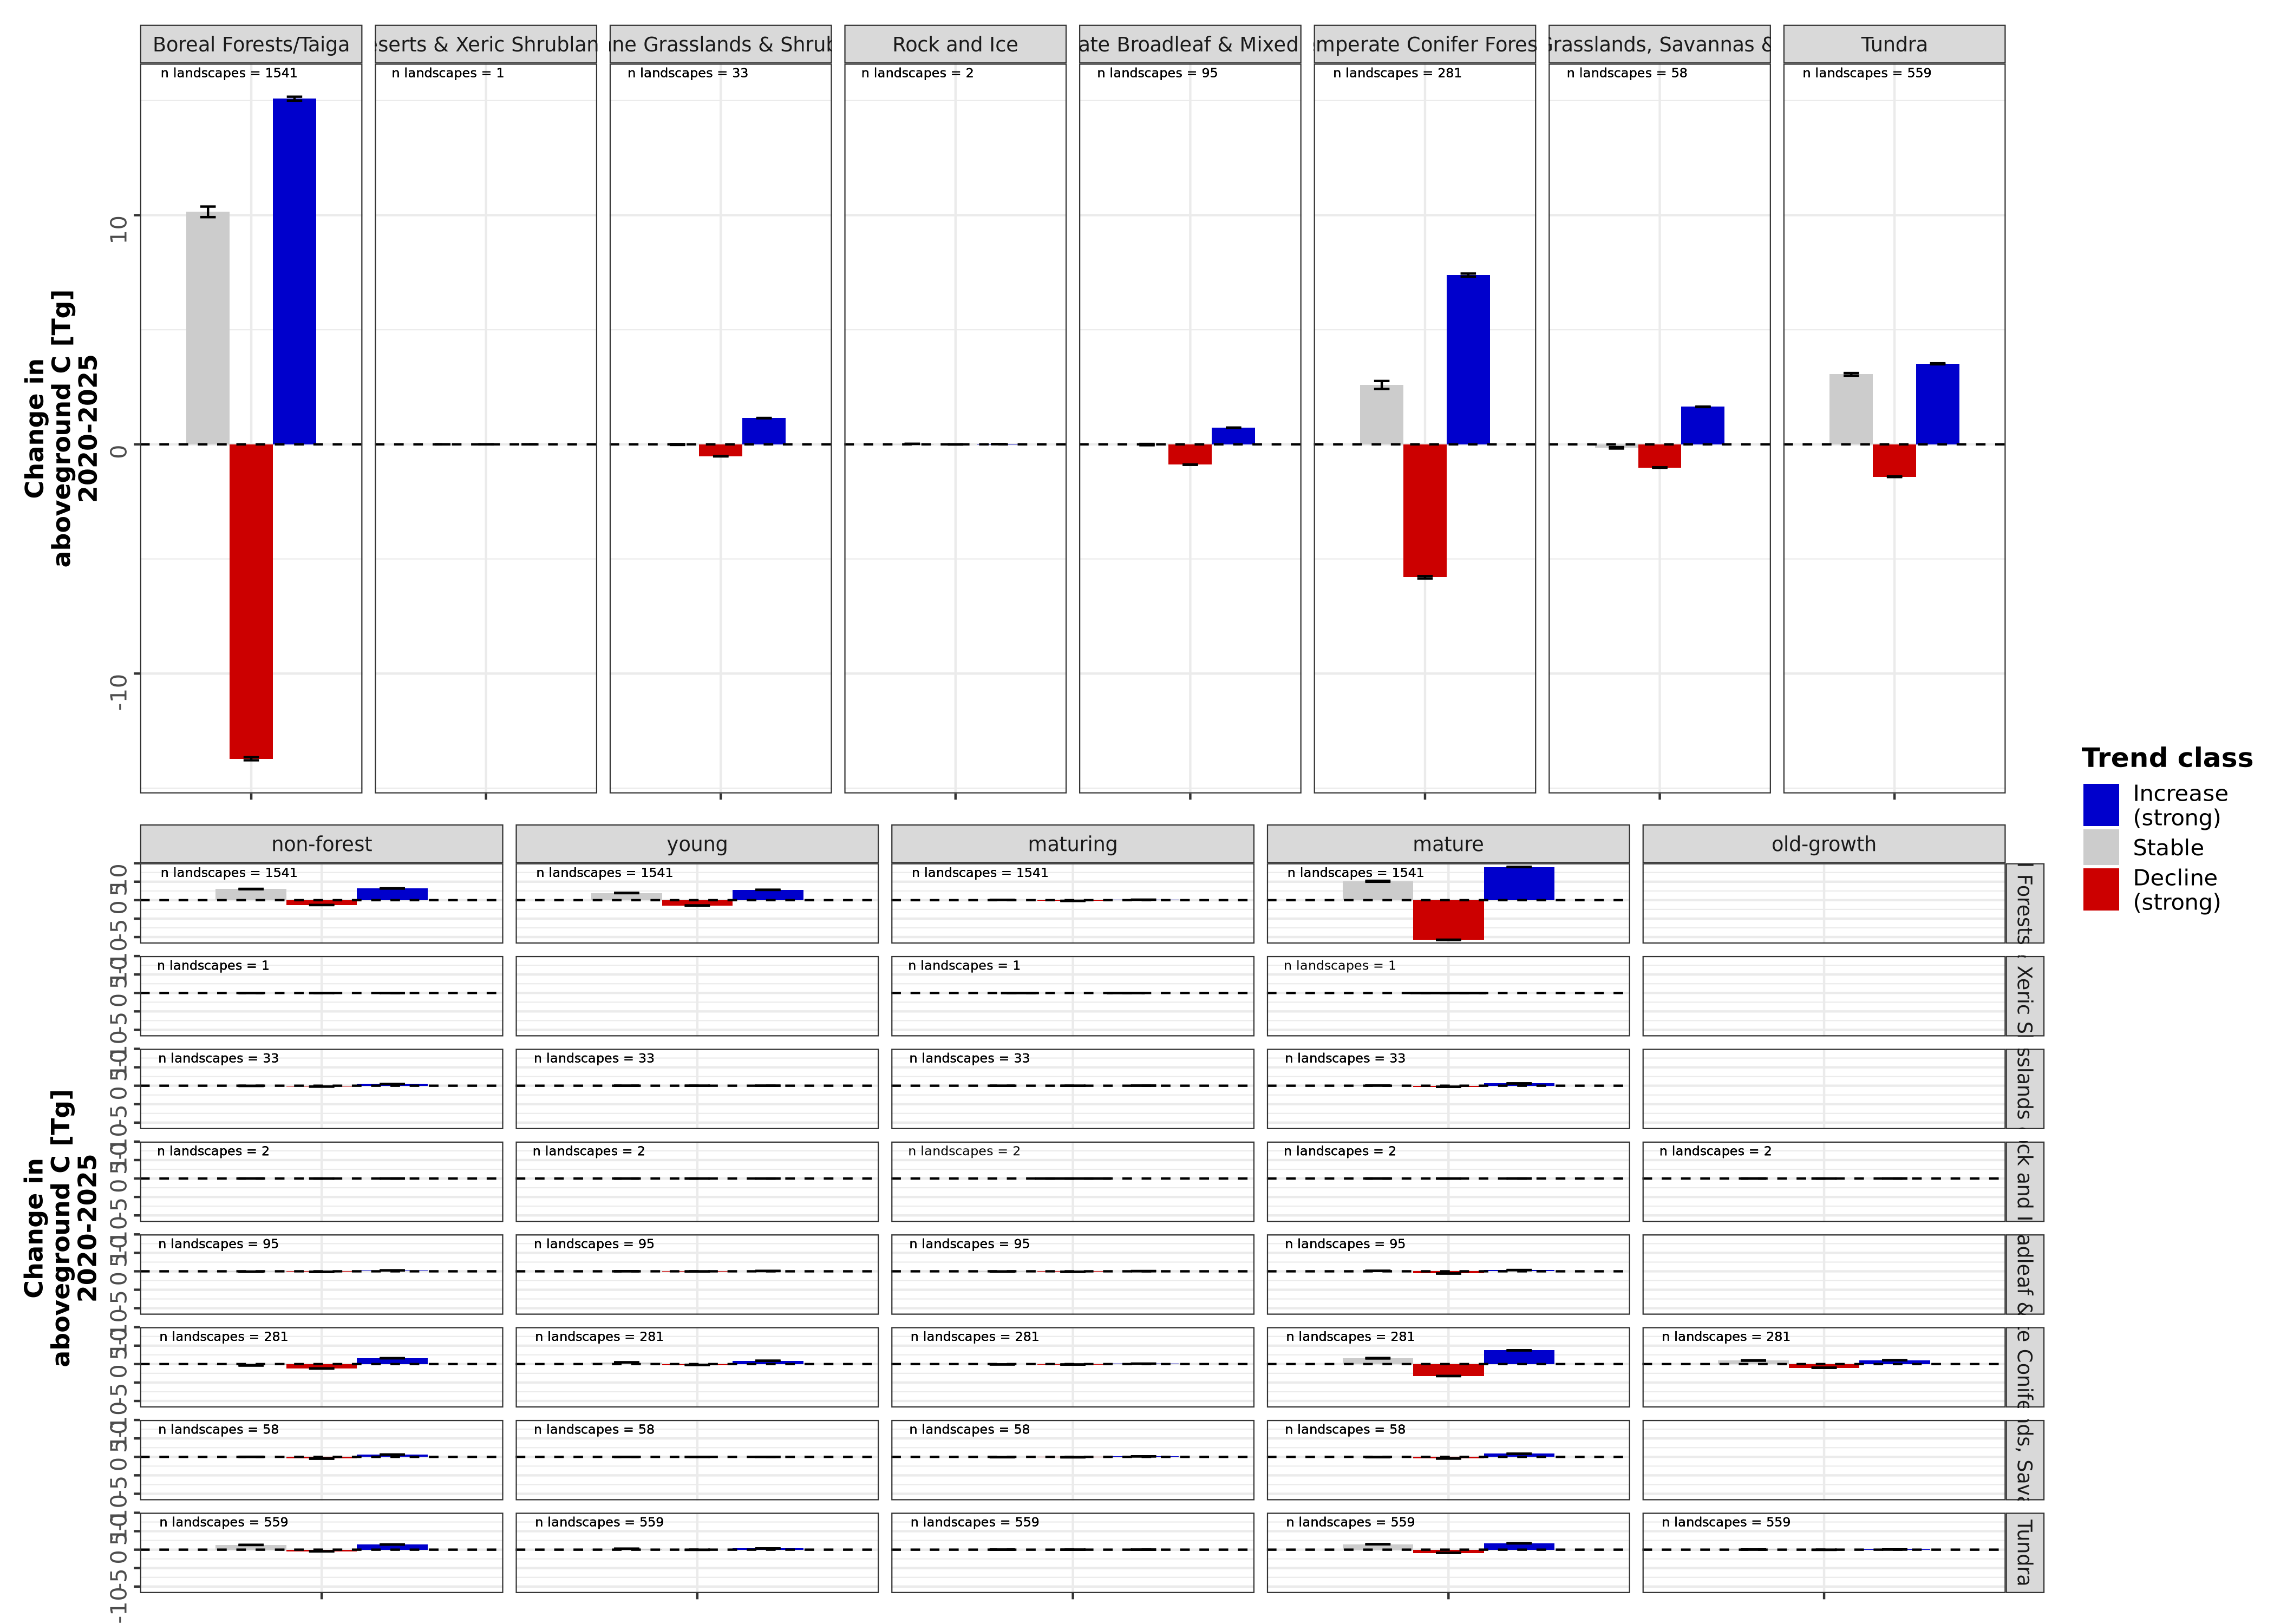

In [79]:
options(repr.plot.width = 14, repr.plot.height = 10, repr.plot.res = 300)

(p_smry_trend / p_smry_age_trend) + plot_layout(guides='collect')

Warning message:
“Removed 600 rows containing missing values or values outside the scale range
(`geom_bar()`).”


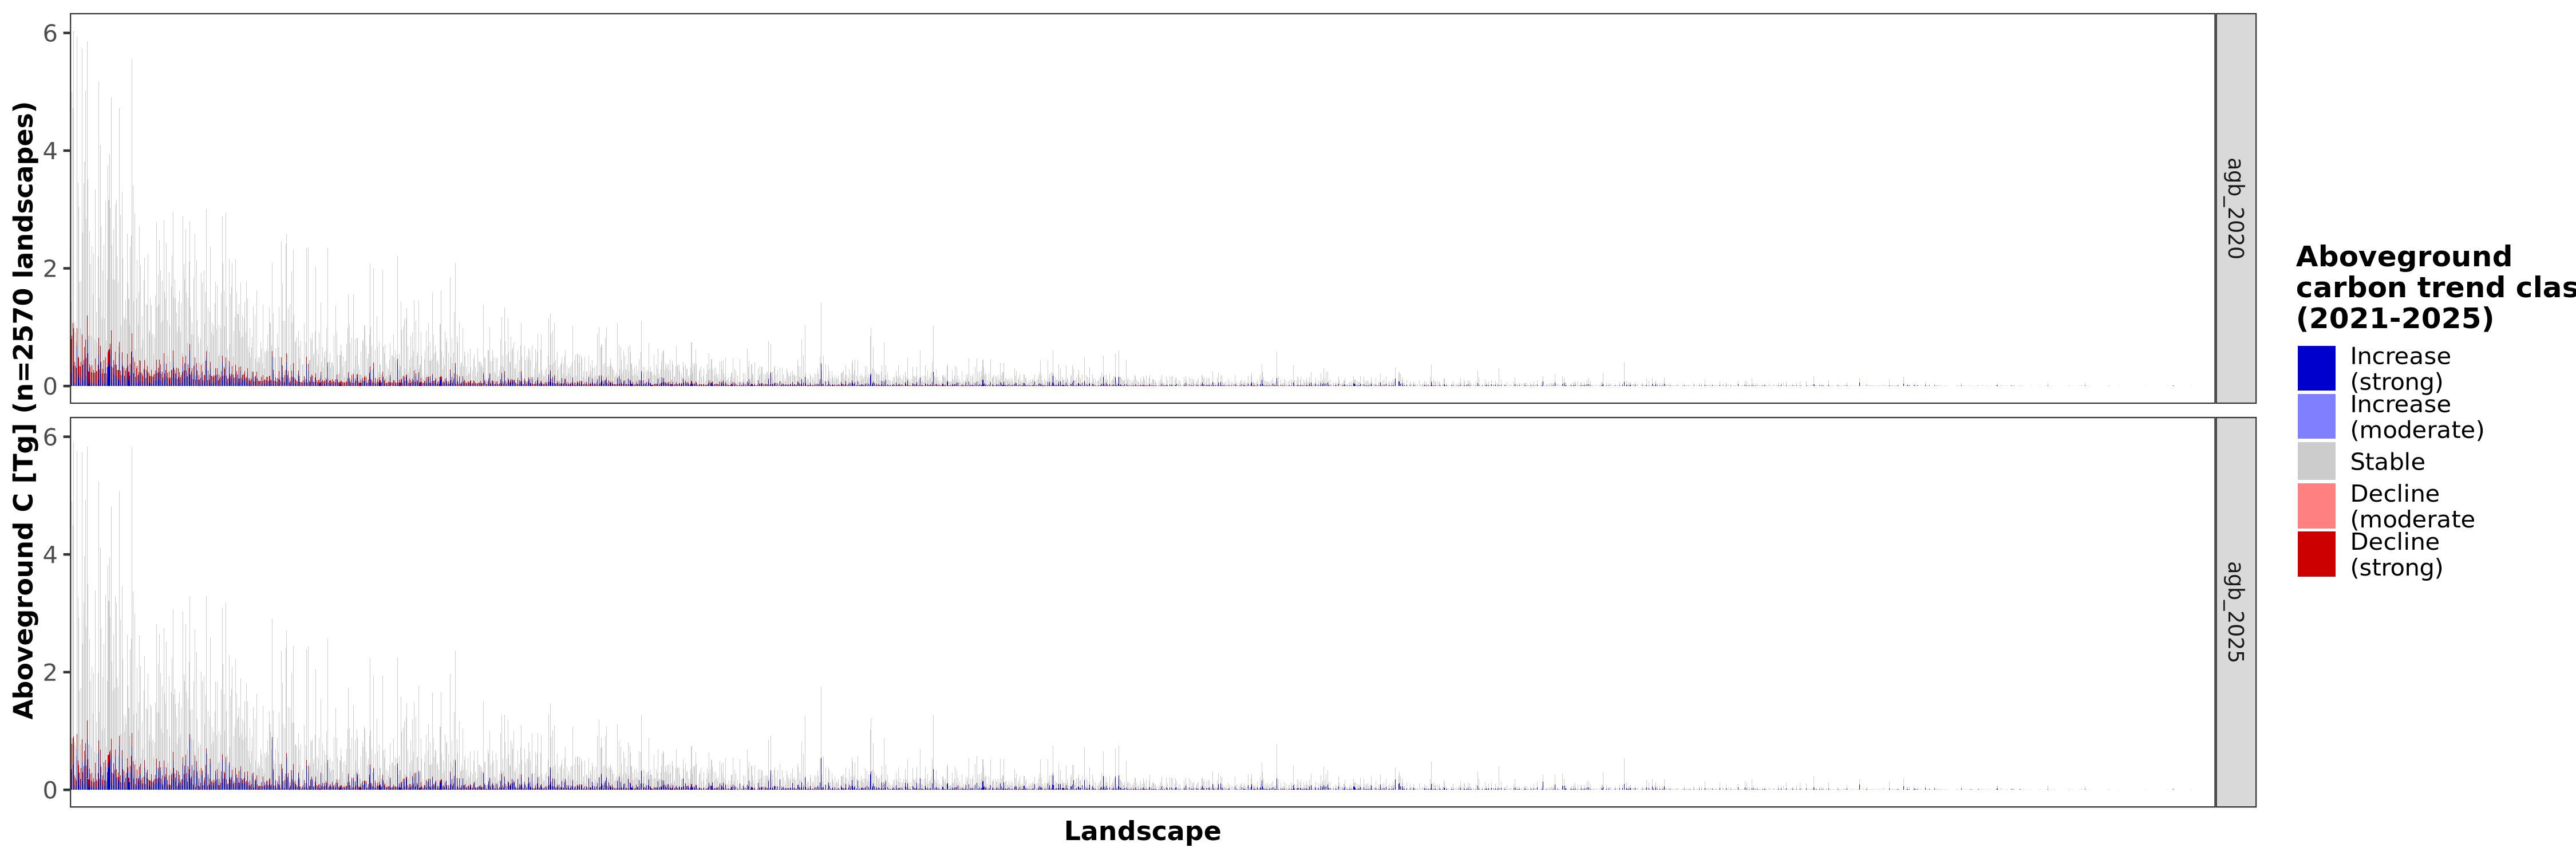

In [53]:
options(repr.plot.width = 15, repr.plot.height = 5, repr.plot.res = 300)

polygon_order = data_polygon_biomass_change_long %>% 
       filter(value_type != 'agb_2020_to_agb_2025') %>%
         filter(trend_class == "strong_decline", value_type == 'agb_2020') %>%
            arrange(desc(biomass_mean_pg), trend_class) %>%
          pull(polygon_id)

# # Save the plot
# ggsave("trend_by_age_class_ordered.png", plot = p1, 
#        width = 12, height = 6, dpi = 300, bg = "white")

# REVERSE the order for the legend display
trend_class_order_reversed <- rev(trend_class_order)

ggplot(data_polygon_biomass_change_long %>% 
       filter(value_type != 'agb_2020_to_agb_2025')

       , aes(x = factor(polygon_id, levels = unique(polygon_order)), y = biomass_mean_pg/2 * 1e3, fill = trend_class)) +
  geom_bar(stat = "identity", position = "stack", width = 0.7) +
  scale_fill_manual(values = trend_colors,
                    name = "Aboveground\ncarbon trend class\n(2021-2025)",
                    labels = trend_labels,
                    breaks = trend_class_order
                   ) +

 scale_y_continuous(
    #labels = percent_format(), 
    name = paste0("Aboveground C [Tg] (n=",length(unique(data_polygon_biomass_change_long$polygon_id))," landscapes)")
 ) +
  labs(
       #title = "Trend Class Distribution by Age Class (Horizontal)",
       #subtitle = "",
       #y = "Proportion"
      x='Landscape'
  ) +
  theme_bw() +
  theme(
    plot.title = element_text(size = 14, face = "bold"),
    plot.subtitle = element_text(size = 12, color = "gray60"),
    axis.text = element_text(size = 10),
    axis.text.x = element_blank(),
    axis.title = element_text(size = 11, face = "bold"),
    legend.position = "right",
      legend.title.position = "top",
    legend.title = element_text(size = 12, face = "bold"),
    legend.text = element_text(size = 10),
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
      axis.ticks.x = element_blank()
  ) + 
facet_grid(value_type~.)



Warning message:
“Removed 150 rows containing missing values or values outside the scale range
(`geom_bar()`).”


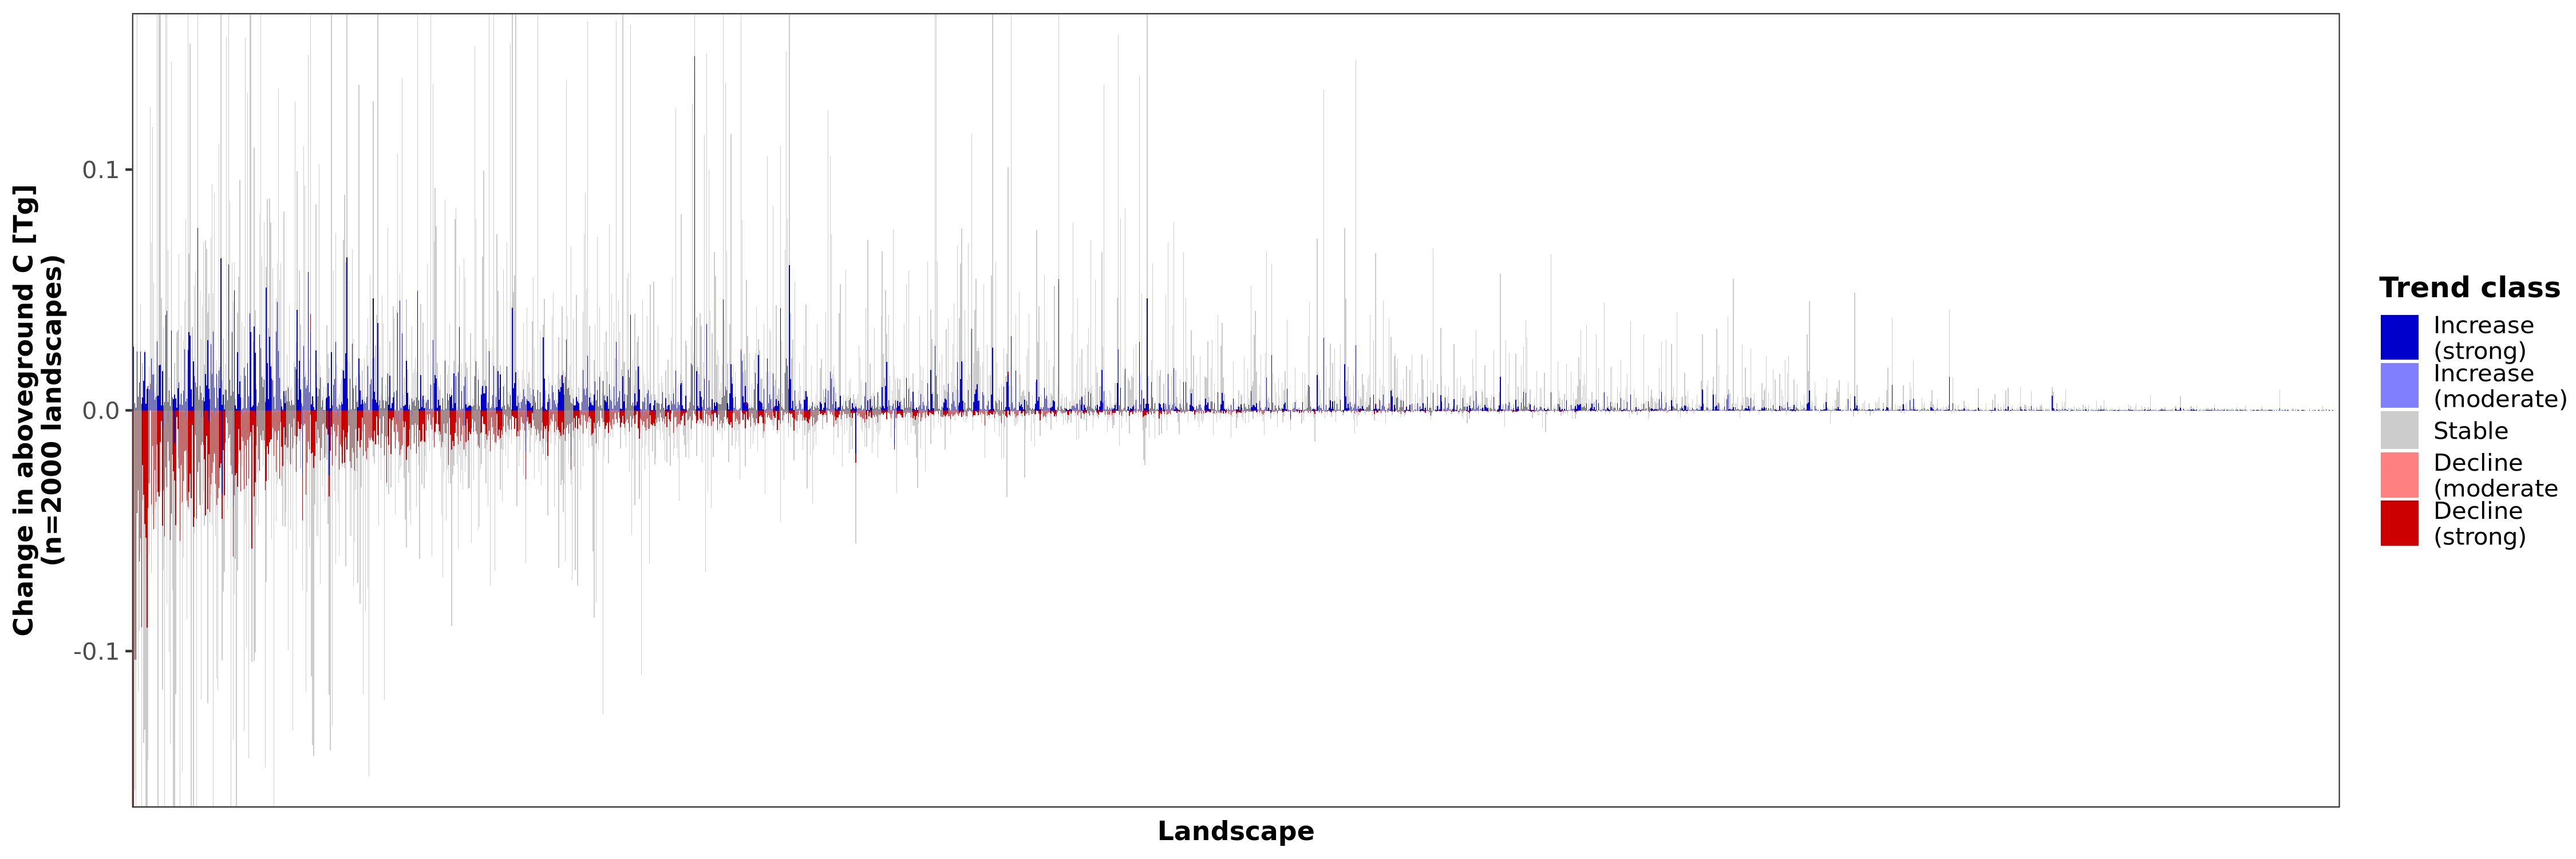

In [14]:
options(repr.plot.width = 15, repr.plot.height = 5, repr.plot.res = 300)

polygon_order = data_polygon_biomass_change_long %>% 
       filter(value_type != 'agb_2020_to_agb_2025') %>%
         filter(trend_class == "strong_decline", value_type == 'agb_2020') %>%
            arrange(desc(biomass_mean_pg), trend_class) %>%
          pull(polygon_id)

# REVERSE the order for the legend display
trend_class_order_reversed <- rev(trend_class_order)

p_landscapes = ggplot(data_polygon_biomass_change_long %>% 
       filter(value_type == 'agb_2020_to_agb_2025')
       , aes(x =  factor(polygon_id, levels = unique(polygon_order)), y = biomass_mean_pg/2 * 1e3, fill = trend_class)) +
  geom_bar(stat = "identity", position = "stack", width = 0.7) +
  scale_fill_manual(values = trend_colors,
                    name = "Trend class",
                    labels = trend_labels,
                    breaks = trend_class_order
                   ) +

 scale_y_continuous(
    #labels = percent_format(), 
    name = paste0("Change in aboveground C [Tg]\n(n=",length(unique(data_polygon_biomass_change_long$polygon_id))," landscapes)")
 ) +
  labs(
       #title = "Trend Class Distribution by Age Class (Horizontal)",
       #subtitle = "",
       #y = "Proportion"
      x='Landscape'
  ) +
  theme_bw() +
  theme(
    plot.title = element_text(size = 14, face = "bold"),
    plot.subtitle = element_text(size = 12, color = "gray60"),
    axis.text = element_text(size = 10),
    axis.text.x = element_blank(),
    axis.title = element_text(size = 11, face = "bold"),
    legend.position = "ight",
      legend.title.position = "top",
    legend.title = element_text(size = 12, face = "bold"),
    legend.text = element_text(size = 10),
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
      axis.ticks.x = element_blank()
  ) + 
coord_cartesian(y=c(-0.15,0.15))# +
#facet_grid(value_type~.)

p_landscapes


Warning message:
“Removed 150 rows containing missing values or values outside the scale range
(`geom_bar()`).”


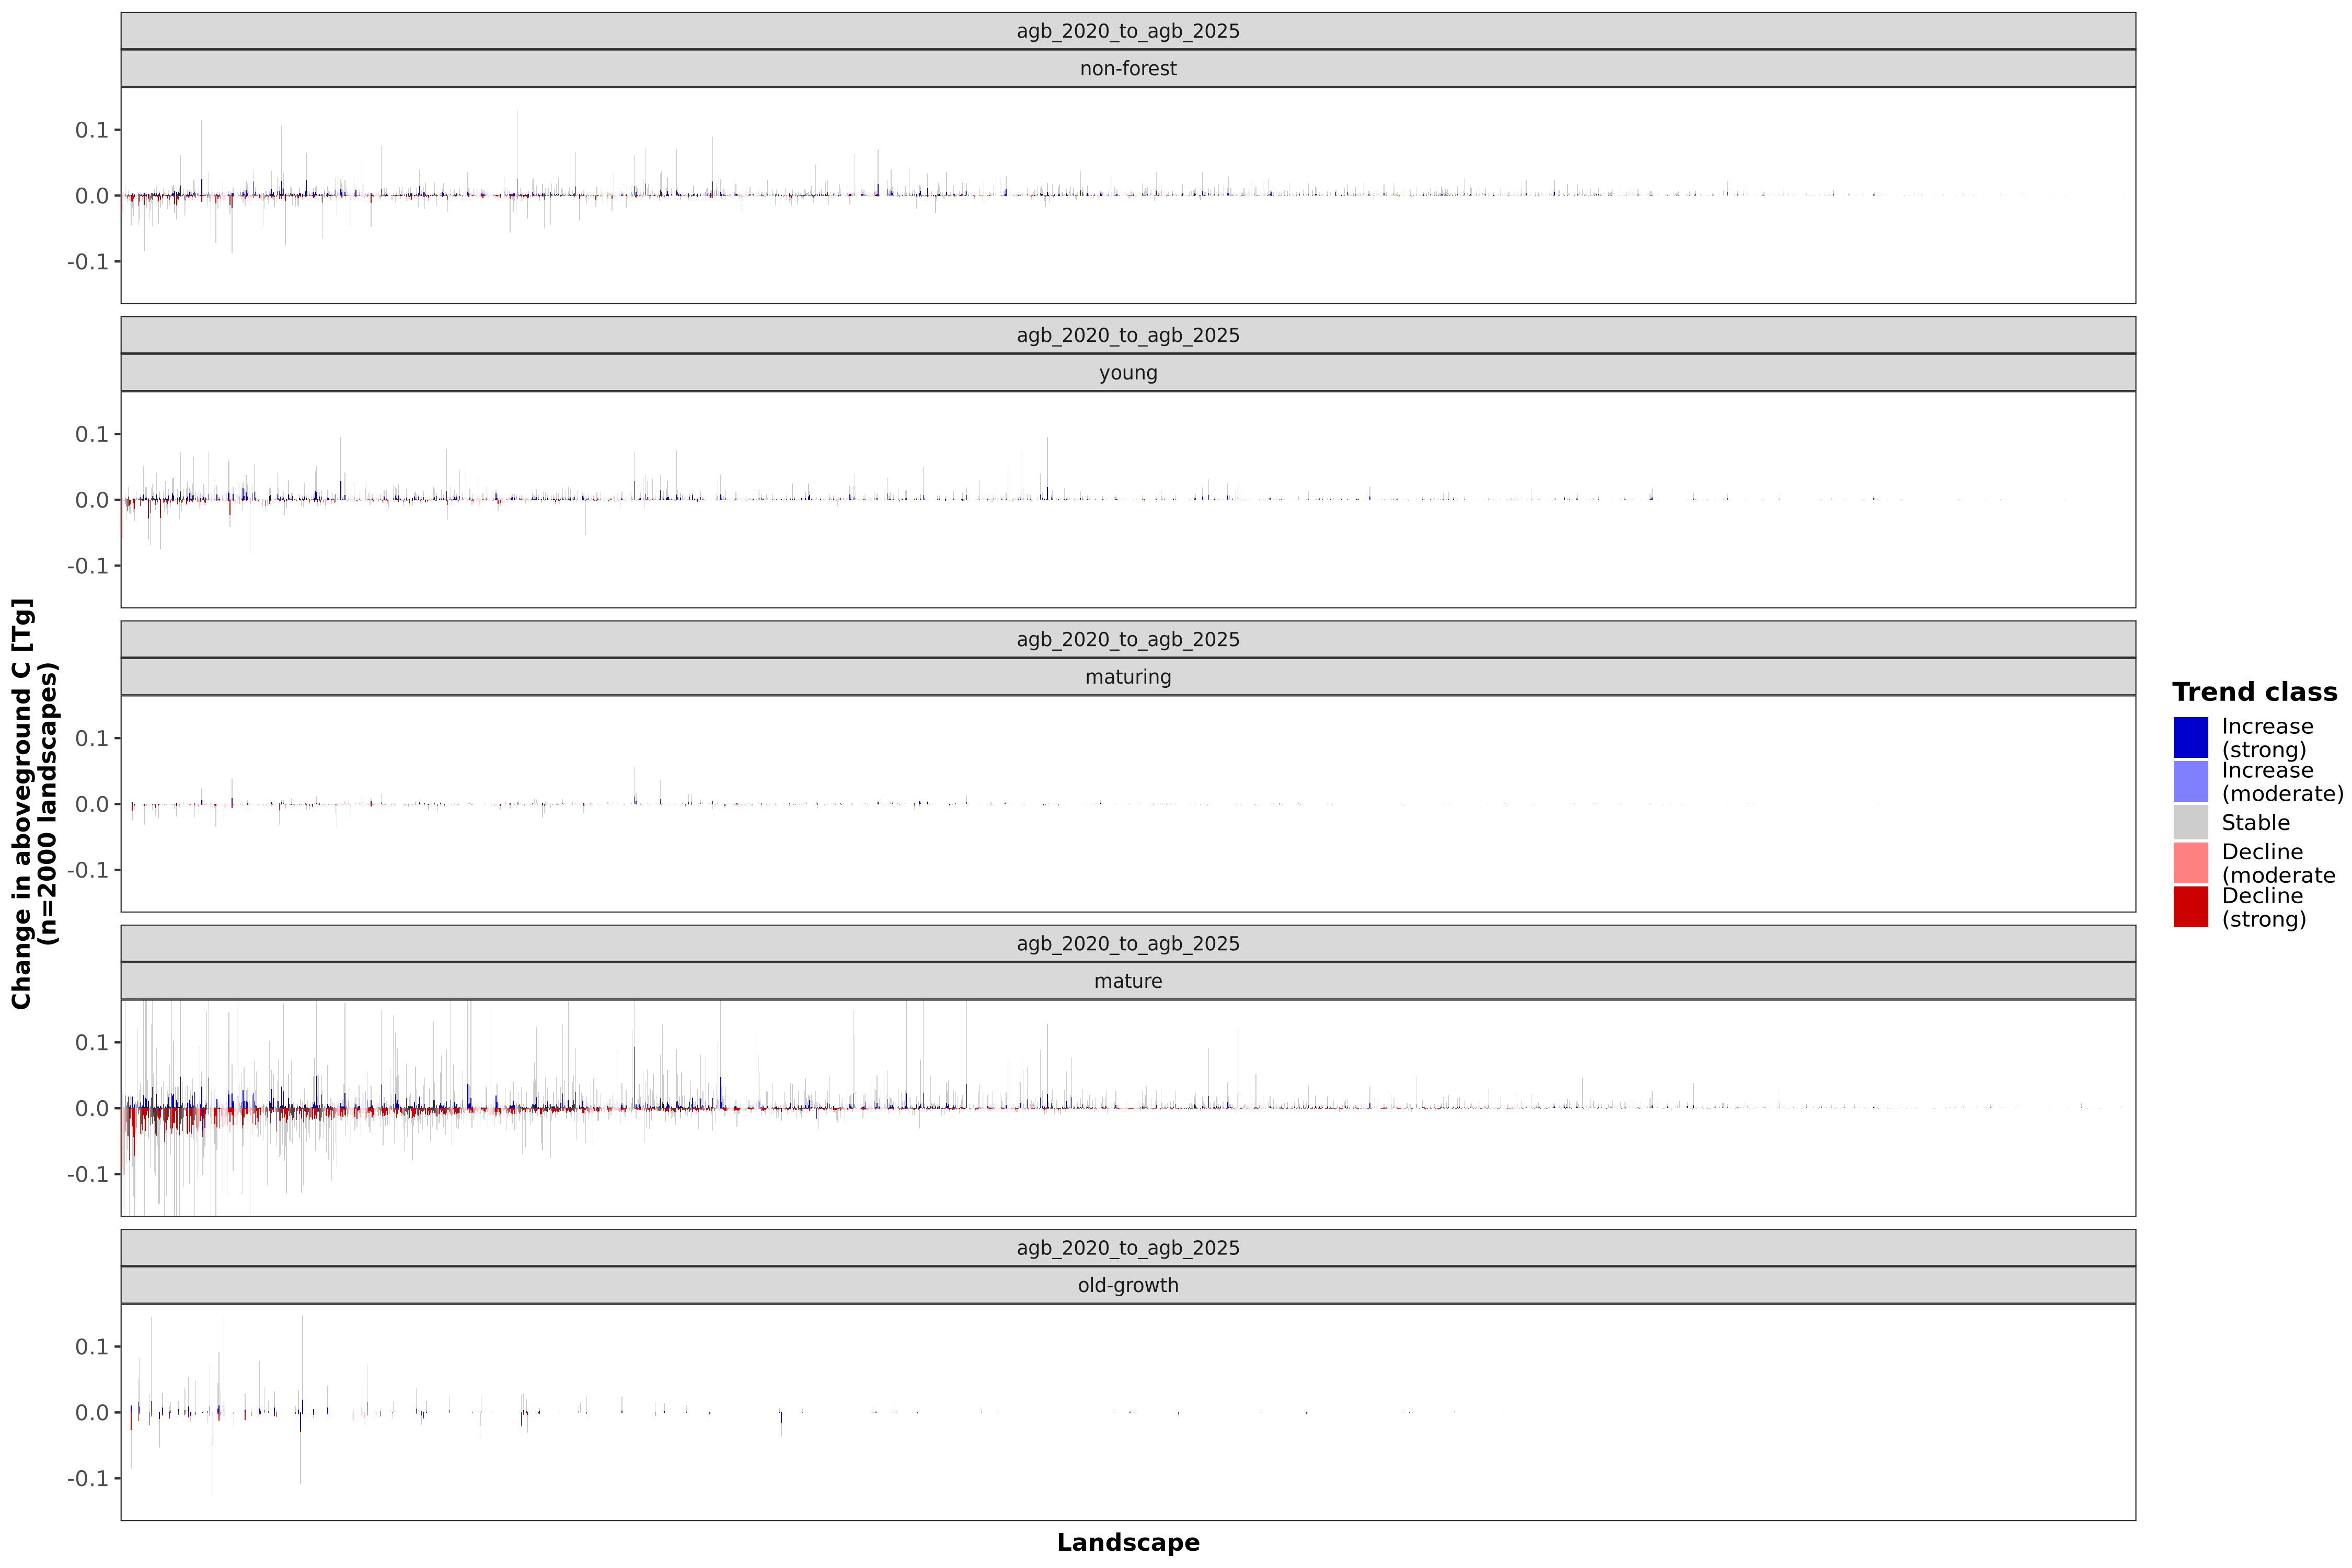

In [15]:
options(repr.plot.width = 15, repr.plot.height = 10, repr.plot.res = 300)


p_landscapes + facet_wrap(value_type~age_class, ncol=1)